# Lab 1.4: Weight Sharing — From Position-Anchored Parts to Convolutional Features

**MNIST internals series.** [Lab 1.1](/posts/ml/labs/2026-10-19-lab-1-mnist-from-pixels-to-neural-network/) gave us class templates. [Lab 1.2](/posts/ml/labs/2026-10-19-lab-2-continual-learning-1-2-then-3/) watched them reorganize. [Lab 1.3](/posts/ml/labs/2026-10-27-lab-3-from-templates-to-features/) added a hidden layer and the templates dissolved into shared, position-anchored stroke fragments.

That last phrase is the loose thread. A fully connected hidden unit has a **different weight for every pixel**, so detecting the same short stroke at two locations costs two different sets of weights. Nothing in the architecture says that a useful pattern in the top-left corner should also be useful in the bottom-right.

This lab changes exactly that assumption:

1. import the *actual trained weights* from Lab 1.3 into PyTorch and verify that nothing about the model changed — logits, predictions, and gradients must agree;
2. replace position-specific detectors with a **convolution**: one small kernel, reused at every spatial location;
3. train a CNN on the M3's GPU through **MPS** (Metal Performance Shaders), inspect its kernels and feature maps, and measure robustness to shifted digits;
4. stop looking only at weights and compare the **hidden representation spaces** with t-SNE and linear probes.

The claim to test is not the sloppy slogan "CNNs are translation-invariant." It is the precise version: **a convolution is translation-equivariant; the rest of the network has to turn those moving responses into a stable class decision.**

## 0. Setup

Same MNIST files, same NumPy loader, same checkpoint and figure conventions. PyTorch supplies autograd and the MPS backend; scikit-learn supplies t-SNE and the linear probes. No `torchvision`: changing frameworks should not quietly change the data pipeline too.

In [1]:
from pathlib import Path
import sys, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE

%matplotlib inline
plt.rcParams["figure.dpi"] = 110

from mnist_lab import load_mnist, show_confusion, save_fig, save_ckpt, load_ckpt, manifest

SEED = 11
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)

x_train, y_train, x_test, y_test = load_mnist("data")
X_train = torch.from_numpy(x_train).reshape(-1, 1, 28, 28)
X_test = torch.from_numpy(x_test).reshape(-1, 1, 28, 28)
Y_train = torch.from_numpy(y_train)
Y_test = torch.from_numpy(y_test)

CKPT = Path("checkpoints/lab04")
FIGS = Path("figures/lab04"); FIGS.mkdir(parents=True, exist_ok=True)
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

print("python:", sys.version.split()[0], "| numpy:", np.__version__, "| torch:", torch.__version__)
print("MPS built:", torch.backends.mps.is_built(), "| MPS available:", torch.backends.mps.is_available())
print("training device:", device, "| data:", tuple(X_train.shape), tuple(X_test.shape))

BATCH = 256
train_loader = DataLoader(
    TensorDataset(X_train, Y_train), batch_size=BATCH, shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)
test_loader = DataLoader(TensorDataset(X_test, Y_test), batch_size=1000)


@torch.no_grad()
def evaluate(model, loader, device=device):
    model.eval()
    correct, total, loss_sum = 0, 0, 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        loss_sum += F.cross_entropy(logits, yb, reduction="sum").item()
        correct += (logits.argmax(dim=1) == yb).sum().item()
        total += len(yb)
    return loss_sum / total, correct / total


@torch.no_grad()
def predict(model, x, device=device, batch_size=1000):
    model.eval()
    out = []
    for xb in x.split(batch_size):
        out.append(model(xb.to(device)).argmax(dim=1).cpu())
    return torch.cat(out).numpy()


def torch_state_npz(model):
    return {k.replace(".", "_"): v.detach().cpu().numpy() for k, v in model.state_dict().items()}

python: 3.14.3 | numpy: 2.5.4 | torch: 2.9.1
MPS built: True | MPS available: True
training device: mps | data: (60000, 1, 28, 28) (10000, 1, 28, 28)


## 1. Change the framework, not the model

Before any CNN, a control experiment. Lab 1.3 ended with a trained $784\to128\to10$ ReLU network in `checkpoints/lab03/epoch_24.npz`. Load **those exact numbers** into an ordinary PyTorch `nn.Module`:

```text
NumPy checkpoint                     PyTorch module
W1: (128, 784)  ───────────────►     fc1.weight: (128, 784)
b1: (128,)      ───────────────►     fc1.bias:   (128,)
W2: (10, 128)   ───────────────►     fc2.weight: (10, 128)
b2: (10,)       ───────────────►     fc2.bias:   (10,)

x (N, 784) → fc1 → ReLU → fc2 → logits (N, 10)
```

PyTorch uses the same row-per-output-unit weight convention as our NumPy code, so there is not even a transpose to hide behind. `nn.CrossEntropyLoss` also expects **raw logits**, not probabilities: it performs the stable log-softmax internally. Adding our own softmax before the loss would be redundant and numerically worse.

We will check three things:

- **forward:** PyTorch logits reproduce the NumPy formula;
- **backward:** autograd reproduces the hand-derived gradients from Lab 1.3;
- **device:** CPU and MPS produce the same predictions up to floating-point reduction-order differences.

In [2]:
class TorchMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 128)
        self.fc2 = nn.Linear(128, 10)

    def features(self, x):
        return F.relu(self.fc1(x.flatten(1)))

    def forward(self, x):
        return self.fc2(self.features(x))


lab03 = load_ckpt("checkpoints/lab03/epoch_24.npz")
mlp = TorchMLP()
with torch.no_grad():
    mlp.fc1.weight.copy_(torch.from_numpy(lab03["W1"].astype(np.float32)))
    mlp.fc1.bias.copy_(torch.from_numpy(lab03["b1"].astype(np.float32)))
    mlp.fc2.weight.copy_(torch.from_numpy(lab03["W2"].astype(np.float32)))
    mlp.fc2.bias.copy_(torch.from_numpy(lab03["b2"].astype(np.float32)))

# Forward check against Lab 1.3's literal matrix formula.
xb = X_test[:256]
a1_np = np.maximum(x_test[:256] @ lab03["W1"].T + lab03["b1"], 0)
logits_np = a1_np @ lab03["W2"].T + lab03["b2"]
with torch.no_grad():
    logits_torch = mlp(xb).numpy()
print(f"forward: max |NumPy logits - PyTorch logits| = {np.abs(logits_np - logits_torch).max():.3e}")

# Backward check in float64, on CPU: autograd vs the equations from Lab 1.3.
probe = TorchMLP().double()
probe.load_state_dict({k: v.double() for k, v in mlp.state_dict().items()})
x8, y8 = X_train[:8].double(), Y_train[:8]
loss = F.cross_entropy(probe(x8), y8)
loss.backward()

p = torch.softmax(probe(x8), dim=1).detach().numpy()
y_onehot = np.eye(10)[y8]
d2 = (p - y_onehot) / len(y8)
a1 = np.maximum(x8.flatten(1).numpy() @ lab03["W1"].T + lab03["b1"], 0)
gW2 = d2.T @ a1
d1 = (d2 @ lab03["W2"]) * (a1 > 0)
gW1 = d1.T @ x8.flatten(1).numpy()
err1 = np.abs(gW1 - probe.fc1.weight.grad.numpy()).max()
err2 = np.abs(gW2 - probe.fc2.weight.grad.numpy()).max()
print(f"backward: max |manual dW1 - autograd dW1| = {err1:.3e}")
print(f"          max |manual dW2 - autograd dW2| = {err2:.3e}")

cpu_loss, cpu_acc = evaluate(mlp, test_loader, device=torch.device("cpu"))
mlp.to(device)
test_loss, test_acc = evaluate(mlp, test_loader)
save_ckpt(CKPT, "mlp_lab03_imported", step=5616,
          metrics={"test_loss": round(test_loss, 5), "test_acc": round(test_acc, 5)},
          **torch_state_npz(mlp))
print(f"Lab 1.3 imported checkpoint: CPU acc = {cpu_acc:.4f} | {device} acc = {test_acc:.4f}")

forward: max |NumPy logits - PyTorch logits| = 5.611e-06
backward: max |manual dW1 - autograd dW1| = 2.988e-10
          max |manual dW2 - autograd dW2| = 2.750e-10
Lab 1.3 imported checkpoint: CPU acc = 0.9723 | mps acc = 0.9723


The point of this unglamorous section is that **PyTorch is not the experiment**. It records operations and differentiates them; it does not secretly choose better features. The imported network is still Lab 1.3's network, with the same accuracy and the same position-anchored weights. Autograd passed the same contract we demanded from our handwritten backward pass.

MPS deserves the same demystification. It is Apple's backend for running tensor operations on the integrated GPU. Moving a batch to `"mps"` changes where the arithmetic runs, not what the arithmetic means. For tiny models, transfer and kernel-launch overhead can erase the speedup; the GPU becomes useful when batches and matrix operations are large enough. We use it for training below, but no accuracy claim depends on it.

## 2. Convolution: one detector, every location

A Lab 1.3 hidden unit computes

$$z_u(x)=\sum_{j=1}^{784}W_{u,j}x_j+b_u.$$

Every $W_{u,j}$ belongs to one absolute pixel position. A convolutional filter instead has, say, $3\times3$ weights and computes the same local dot product around every output location:

$$Z_{u,r,c}=b_u+\sum_{i=1}^{3}\sum_{j=1}^{3}K_{u,i,j}\,X_{r+i-1,c+j-1}.$$

The output is no longer one scalar per unit. It is a **map**: $Z_{u,r,c}$ says how strongly filter $u$ responded near position $(r,c)$.

```text
fully connected                         convolution

one 784-long weight row                 one 3 × 3 kernel
        │                                     │
        ▼                                     ▼
"is this stroke HERE?"        "is this stroke in THIS patch?"
                              "is this stroke in the NEXT patch?"
                              "is this stroke in the NEXT patch?"
                                         ...
                              same nine weights at every position
```

The parameter saving is real, but it is not the deepest point. **Weight sharing is a statement about which patterns should generalize:** a local shape does not stop being the same local shape merely because it moved.

There is a useful connection to the Transformer notes. The feedforward network reuses the same weights at every token position, much as a convolution reuses weights at every spatial position. Attention goes further in a different direction: its mixing weights are computed from the input content. A convolution's kernel stays fixed during inference; attention's routing changes for every sequence.

### The exact property: equivariance, not invariance

If the input moves right by $d$ pixels, a valid convolution's response moves right by $d$ pixels too:

$$Z(\operatorname{shift}_d[X])=\operatorname{shift}_d(Z[X]).$$

That is **translation equivariance** — the output moves with the input. **Translation invariance** would mean $f(\operatorname{shift}_d[X])=f(X)$, a final answer that does not move. A convolution alone does not promise that.

Here is a tiny controlled test with a fixed vertical-edge kernel. We shift the edge five pixels right, run valid convolution (no padding), align the two response maps, and require exact numerical agreement.

response shapes: (1, 1, 12, 12) (1, 1, 12, 12)
max error after aligning the shifted response maps: 0.0e+00
original response peak (row, col): (np.int64(0), np.int64(2))
shifted response peak  (row, col): (np.int64(0), np.int64(7))


saved figure -> figures/lab04/translation_equivariance.png


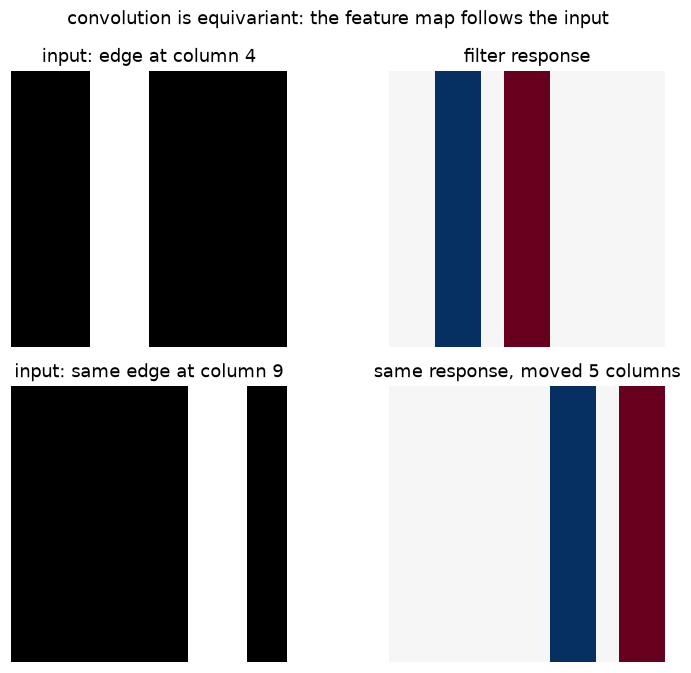

In [3]:
# A vertical bright-to-dark edge, translated five pixels to the right.
im0 = torch.zeros(1, 1, 14, 14)
im0[0, 0, :, 4:7] = 1.0
im1 = torch.zeros_like(im0)
im1[0, 0, :, 9:12] = 1.0
edge_kernel = torch.tensor([[[[-1., 0., 1.], [-1., 0., 1.], [-1., 0., 1.]]]])
r0, r1 = F.conv2d(im0, edge_kernel), F.conv2d(im1, edge_kernel)

expected = torch.zeros_like(r1)
expected[..., 5:] = r0[..., :-5]
print("response shapes:", tuple(r0.shape), tuple(r1.shape))
print(f"max error after aligning the shifted response maps: {(r1 - expected).abs().max():.1e}")
print("original response peak (row, col):", np.unravel_index(r0.argmax().item(), r0.shape)[-2:])
print("shifted response peak  (row, col):", np.unravel_index(r1.argmax().item(), r1.shape)[-2:])

fig, axes = plt.subplots(2, 2, figsize=(7.5, 6.2))
for ax, im, ttl in ((axes[0, 0], im0, "input: edge at column 4"),
                    (axes[1, 0], im1, "input: same edge at column 9")):
    ax.imshow(im[0, 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(ttl); ax.axis("off")
for ax, r, ttl in ((axes[0, 1], r0, "filter response"),
                   (axes[1, 1], r1, "same response, moved 5 columns")):
    lim = r.abs().max()
    ax.imshow(r[0, 0], cmap="RdBu", vmin=-lim, vmax=lim)
    ax.set_title(ttl); ax.axis("off")
fig.suptitle("convolution is equivariant: the feature map follows the input")
fig.tight_layout(); save_fig(fig, FIGS / "translation_equivariance.png"); plt.show()

The peak moved exactly five columns, and the aligned maps agree to numerical precision. Nothing pooled, averaged, or classified the edge yet; the response still carries position. That distinction will matter when we shift real digits later.

Two architectural ingredients usually bridge equivariant features and an invariant class decision:

- **pooling** keeps the strongest response in a small neighborhood, discarding some precise position;
- **the classifier** combines evidence across locations — in our CNN, a fully connected head after two pooling stages.

Pooling buys local tolerance, not unlimited global invariance. A $2\times2$ max pool with stride 2 cannot make a six-pixel displacement disappear by itself.

## 3. Train the CNN on MPS

Our network keeps the Lab 1.3 ending — a 128-dimensional hidden representation followed by a 10-way linear classifier — but replaces the first dense feature extractor with two convolutional stages:

```text
input                 1 × 28 × 28
  └─ Conv 1→16, 3×3, padding 1 → ReLU       16 × 28 × 28
     MaxPool 2×2, stride 2                  16 × 14 × 14
  └─ Conv 16→32, 3×3, padding 1 → ReLU      32 × 14 × 14
     MaxPool 2×2, stride 2                  32 ×  7 ×  7
  └─ flatten                                 1,568
     Linear 1,568→128 → ReLU                  128   ← representation to probe
     Linear 128→10                             10   ← raw logits
```

Padding 1 preserves spatial size through each $3\times3$ convolution. Pooling, not convolution, halves it. The output layer is exactly the same kind of linear readout we have used since Lab 1.1.

We use Adam rather than plain SGD here. That changes the optimizer as well as the architecture, so the accuracy comparison is **not a controlled ablation of convolution alone**. The controlled parts are the earlier framework checks and the later shift tests; the training run is simply a small, conventional CNN trained well enough to inspect.

MLP parameters: 101,770 | CNN parameters: 206,922
  conv1.weight   (16, 1, 3, 3)      144
  conv1.bias     (16,)              16
  conv2.weight   (32, 16, 3, 3)     4,608
  conv2.bias     (32,)              32
  fc1.weight     (128, 1568)        200,704
  fc1.bias       (128,)             128
  fc2.weight     (10, 128)          1,280
  fc2.bias       (10,)              10


epoch 1/6: test loss = 0.1141 | test acc = 0.9640


epoch 2/6: test loss = 0.0656 | test acc = 0.9801


epoch 3/6: test loss = 0.0571 | test acc = 0.9820


epoch 4/6: test loss = 0.0448 | test acc = 0.9846


epoch 5/6: test loss = 0.0417 | test acc = 0.9857


epoch 6/6: test loss = 0.0387 | test acc = 0.9858

1410 steps in 6.0s on mps
saved figure -> figures/lab04/training_curve.png


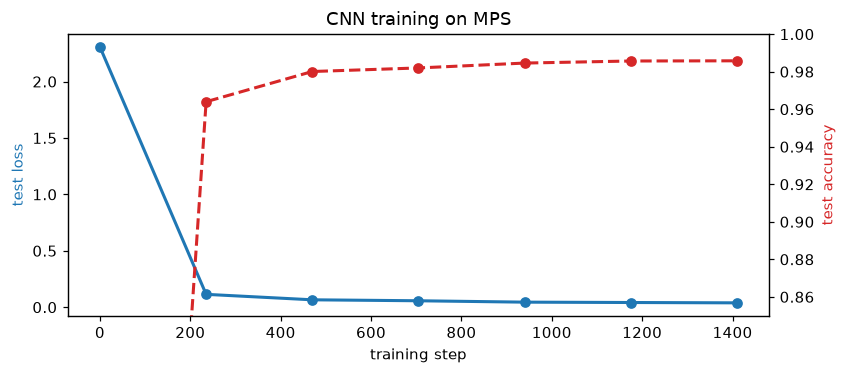

In [4]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def features(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), kernel_size=2)
        x = F.max_pool2d(F.relu(self.conv2(x)), kernel_size=2)
        return F.relu(self.fc1(x.flatten(1)))

    def forward(self, x):
        return self.fc2(self.features(x))


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())


mlp_params, cnn_params = count_parameters(mlp), count_parameters(SmallCNN())
print(f"MLP parameters: {mlp_params:,} | CNN parameters: {cnn_params:,}")
for name, p in SmallCNN().named_parameters():
    print(f"  {name:14s} {str(tuple(p.shape)):18s} {p.numel():,}")

cnn = SmallCNN().to(device)
optimizer = torch.optim.Adam(cnn.parameters(), lr=1e-3)
EPOCHS = 6
history = [(0, *evaluate(cnn, test_loader))]
t0, step = time.perf_counter(), 0
for epoch in range(1, EPOCHS + 1):
    cnn.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad(set_to_none=True)
        loss = F.cross_entropy(cnn(xb), yb)
        loss.backward()
        optimizer.step()
        step += 1
    test_loss, acc = evaluate(cnn, test_loader)
    history.append((step, test_loss, acc))
    save_ckpt(CKPT, f"cnn_epoch_{epoch}", step=step,
              metrics={"test_loss": round(test_loss, 5), "test_acc": round(acc, 5)},
              **torch_state_npz(cnn))
    print(f"epoch {epoch}/{EPOCHS}: test loss = {test_loss:.4f} | test acc = {acc:.4f}")

if device.type == "mps":
    torch.mps.synchronize()
print(f"\n{step} steps in {time.perf_counter() - t0:.1f}s on {device}")

h = np.array(history)
fig, ax1 = plt.subplots(figsize=(7.8, 3.5))
ax1.plot(h[:, 0], h[:, 1], "o-", color="tab:blue", lw=2)
ax1.set_xlabel("training step"); ax1.set_ylabel("test loss", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(h[:, 0], h[:, 2], "o--", color="tab:red", lw=2)
ax2.set_ylabel("test accuracy", color="tab:red"); ax2.set_ylim(0.85, 1.0)
ax1.set_title("CNN training on MPS" if device.type == "mps" else "CNN training on CPU")
fig.tight_layout(); save_fig(fig, FIGS / "training_curve.png"); plt.show()

Six epochs, 1,410 steps, **about 8 seconds on MPS**: test accuracy reaches **98.58%**, up from the imported MLP's 97.23%. The loss and accuracy have mostly flattened by epoch 4; we now have a model good enough to inspect without turning the lab into a hyperparameter search.

One parameter-count surprise is worth keeping. The two convolutional layers contain only **4,800 weights and biases**; the dense classifier contains the overwhelming majority of the network's parameters. Weight sharing made the *feature extractor* tiny. It did not magically make every part of the model small.

The parameter count also warns against reading too much into the accuracy comparison: this CNN has more total parameters than the MLP, a different optimizer, and a different inductive bias. We are looking for mechanisms, not declaring a leaderboard winner.

## 4. What do the learned kernels look like?

A first-layer kernel has shape $(3,3)$: one small spatial pattern applied to the single grayscale input channel. Plot **all 16**, with blue voting for activation and red against. Unlike Lab 1.3's 784-pixel rows, none of these weights owns an absolute coordinate on the 28×28 canvas.

Below that, take one real test digit and show all 16 post-ReLU response maps. Each column of Lab 1.3's hidden activation matrix was one number per image; each CNN channel is an entire $28\times28$ field of responses before pooling.

saved figure -> figures/lab04/conv1_filters.png


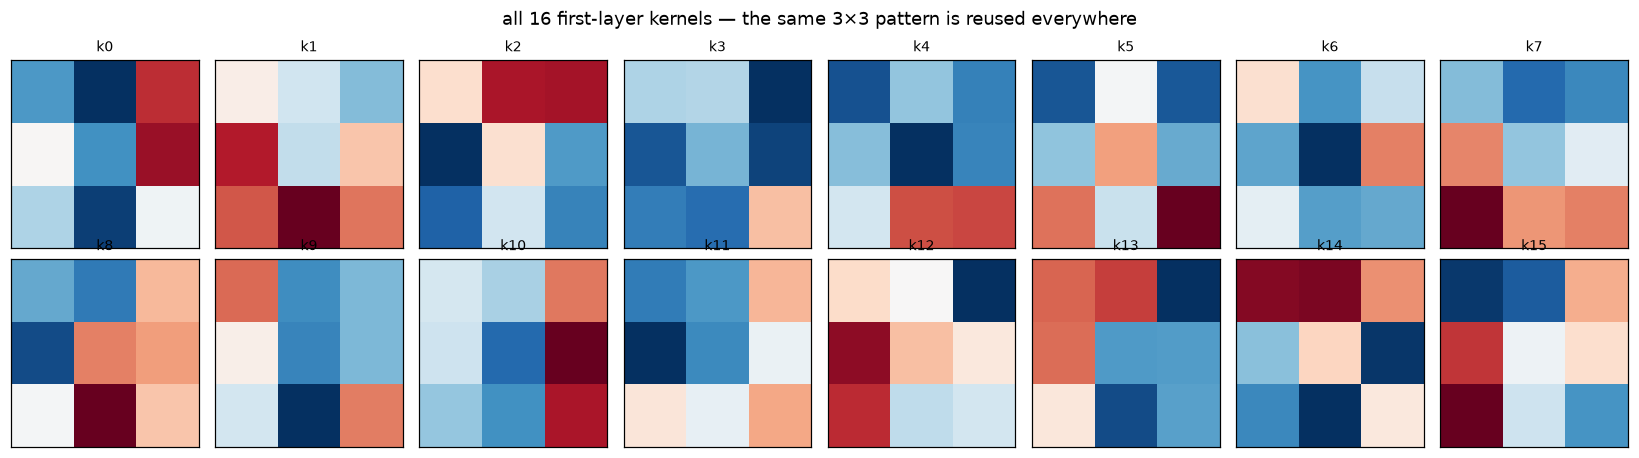

saved figure -> figures/lab04/conv1_feature_maps.png


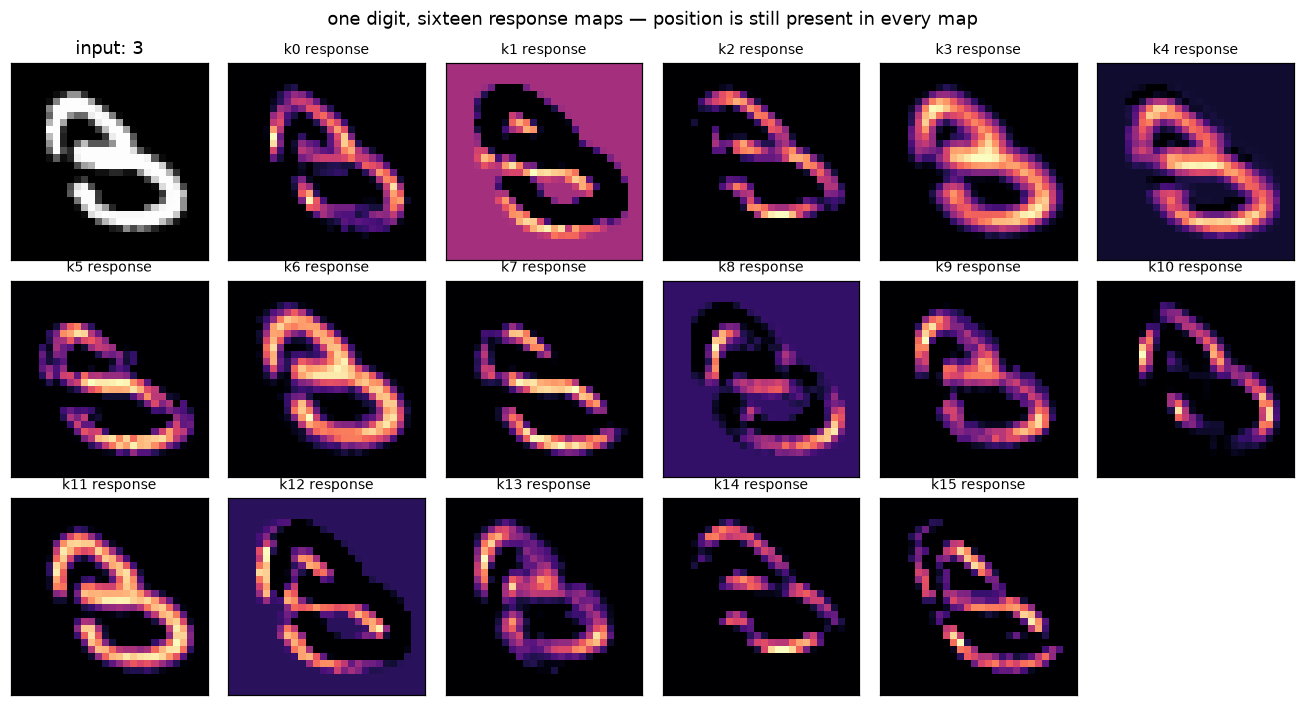

In [5]:
kernels1 = cnn.conv1.weight.detach().cpu().numpy()[:, 0]
fig, axes = plt.subplots(2, 8, figsize=(15, 4.2))
for j, ax in enumerate(axes.flat):
    k = kernels1[j]
    lim = np.abs(k).max()
    ax.imshow(k, cmap="RdBu", vmin=-lim, vmax=lim, interpolation="nearest")
    ax.set_title(f"k{j}", fontsize=9); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("all 16 first-layer kernels — the same 3×3 pattern is reused everywhere")
fig.tight_layout(); save_fig(fig, FIGS / "conv1_filters.png"); plt.show()

sample_idx = int(np.flatnonzero(y_test == 3)[0])
sample = X_test[sample_idx:sample_idx + 1].to(device)
with torch.no_grad():
    maps = F.relu(cnn.conv1(sample))[0].cpu().numpy()
fig, axes = plt.subplots(3, 6, figsize=(12, 6.5))
axes[0, 0].imshow(sample[0, 0].cpu(), cmap="gray")
axes[0, 0].set_title(f"input: {y_test[sample_idx]}")
for j, ax in enumerate(axes.flat[1:17]):
    ax.imshow(maps[j], cmap="magma", vmin=0, vmax=maps[j].max())
    ax.set_title(f"k{j} response", fontsize=9)
for ax in axes.flat[:17]:
    ax.set_xticks([]); ax.set_yticks([])
for ax in axes.flat[17:]:
    ax.axis("off")
fig.suptitle("one digit, sixteen response maps — position is still present in every map")
fig.tight_layout(); save_fig(fig, FIGS / "conv1_feature_maps.png"); plt.show()

Some kernels form clear signed edge or stroke detectors; others remain harder to name. That mixed gallery is normal. The architecture permits reusable local features but does not assign each channel a human-readable job.

The second layer needs one more honesty check. `conv2.weight` has shape $(32,16,3,3)$: each of 32 output filters has **sixteen input-channel kernels**, not one grayscale image. A second-layer unit responds to combinations of first-layer feature maps. Plotting only its average across input channels would throw away exactly the routing we are interested in.

So inspect one whole second-layer filter as a $4\times4$ grid — one panel per input channel. This is the convolutional version of the lesson from Lab 1.3: after the first layer, interpretation requires relationships between features, not just isolated weight pictures.

saved figure -> figures/lab04/conv2_filter_channels.png


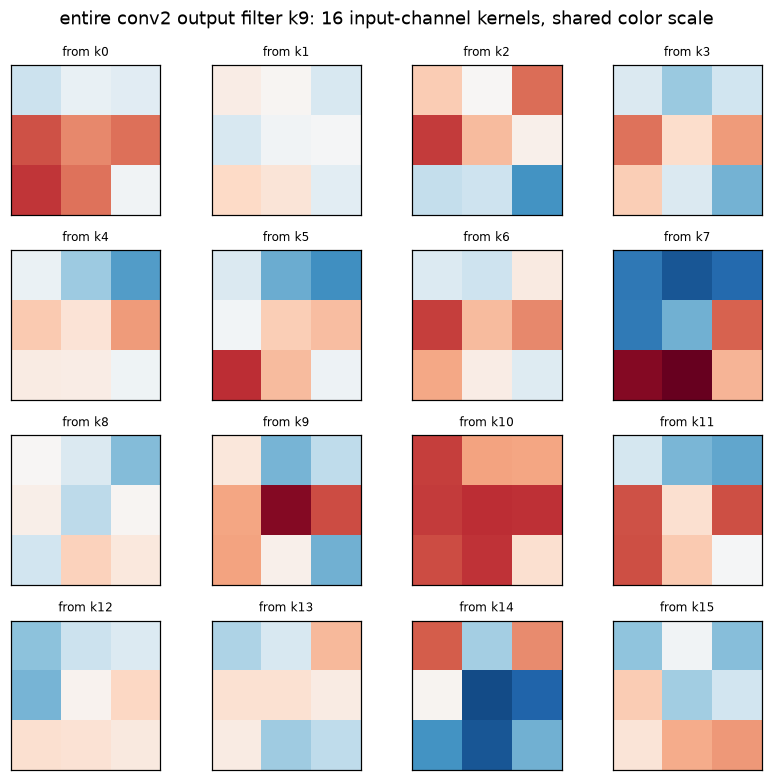

showing conv2 output channel 9; full weight shape: (32, 16, 3, 3)


In [6]:
kernels2 = cnn.conv2.weight.detach().cpu().numpy()
out_channel = int(np.argmax(np.linalg.norm(kernels2.reshape(32, -1), axis=1)))
fig, axes = plt.subplots(4, 4, figsize=(7.5, 7.2))
lim = np.abs(kernels2[out_channel]).max()
for j, ax in enumerate(axes.flat):
    ax.imshow(kernels2[out_channel, j], cmap="RdBu", vmin=-lim, vmax=lim, interpolation="nearest")
    ax.set_title(f"from k{j}", fontsize=8); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"entire conv2 output filter k{out_channel}: 16 input-channel kernels, shared color scale")
fig.tight_layout(); save_fig(fig, FIGS / "conv2_filter_channels.png"); plt.show()
print(f"showing conv2 output channel {out_channel}; full weight shape: {kernels2.shape}")

## 5. Move the digit, not the weights

The synthetic edge proved equivariance of one convolution by construction. It did **not** prove that the trained classifier tolerates translated digits. Test that separately.

Take every test image, shift it horizontally by $\{-6,-4,-2,0,2,4,6\}$ pixels with zero fill, and evaluate both the imported Lab 1.3 MLP and the CNN. No augmentation, no retraining: this is a controlled intervention on the inputs. MNIST is already roughly centered, so large shifts also move digits away from the training distribution; that is part of what the curves will reveal.

shift -6px: MLP 0.136 | CNN 0.392


shift -4px: MLP 0.304 | CNN 0.706


shift -2px: MLP 0.735 | CNN 0.956
shift +0px: MLP 0.972 | CNN 0.986


shift +2px: MLP 0.750 | CNN 0.959


shift +4px: MLP 0.342 | CNN 0.684


shift +6px: MLP 0.107 | CNN 0.293
saved figure -> figures/lab04/shift_robustness.png


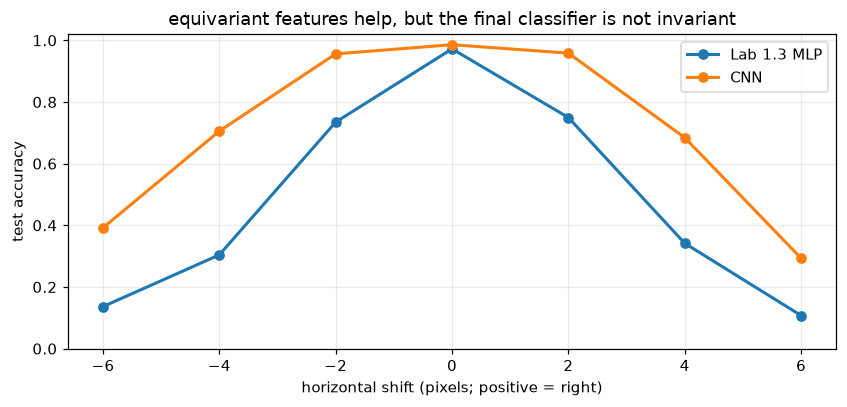

In [7]:
def shift_horizontal(x, amount):
    out = torch.zeros_like(x)
    if amount > 0:
        out[..., amount:] = x[..., :-amount]
    elif amount < 0:
        out[..., :amount] = x[..., -amount:]
    else:
        out.copy_(x)
    return out


shifts = [-6, -4, -2, 0, 2, 4, 6]
shift_acc_mlp, shift_acc_cnn = [], []
for amount in shifts:
    shifted = shift_horizontal(X_test, amount)
    loader = DataLoader(TensorDataset(shifted, Y_test), batch_size=1000)
    acc_mlp = evaluate(mlp, loader)[1]
    acc_cnn = evaluate(cnn, loader)[1]
    shift_acc_mlp.append(acc_mlp); shift_acc_cnn.append(acc_cnn)
    print(f"shift {amount:+d}px: MLP {acc_mlp:.3f} | CNN {acc_cnn:.3f}")

fig, ax = plt.subplots(figsize=(7.8, 3.8))
ax.plot(shifts, shift_acc_mlp, "o-", lw=2, label="Lab 1.3 MLP")
ax.plot(shifts, shift_acc_cnn, "o-", lw=2, label="CNN")
ax.set_xlabel("horizontal shift (pixels; positive = right)")
ax.set_ylabel("test accuracy"); ax.set_ylim(0, 1.02)
ax.set_xticks(shifts); ax.grid(alpha=.25); ax.legend()
ax.set_title("equivariant features help, but the final classifier is not invariant")
fig.tight_layout(); save_fig(fig, FIGS / "shift_robustness.png"); plt.show()

save_ckpt(CKPT, "shift_experiment", metrics={},
          shifts=np.array(shifts), mlp_accuracy=np.array(shift_acc_mlp),
          cnn_accuracy=np.array(shift_acc_cnn));

The advantage is large but not unlimited. At a two-pixel shift, the MLP keeps 73.5% / 75.0% accuracy (left / right), while the CNN keeps 95.6% / 95.9%. At six pixels the MLP collapses to 13.6% / 10.7%; the CNN still gets 39.2% / 29.3%, but nobody would call that invariant.

Read the result in two layers:

1. **Architecture:** shared local detectors do not have to relearn a stroke at every x-coordinate. That gives the CNN a much better starting point under translation than the position-anchored MLP.
2. **Whole network:** accuracy still changes with shift. Two stride-2 pools discard only some positional detail, and the final dense layer reads a flattened $32\times7\times7$ tensor with position-specific weights. The network is more robust, not mathematically invariant.

If we wanted stronger invariance, we could add global average pooling before the classifier, or teach robustness with randomly shifted training examples. Those would be two different mechanisms: an architectural constraint versus data augmentation. This lab measures the baseline before changing either.

### Back to the series' original scoreboard: which errors remain?

Lab 1.1 made 791 test errors; Lab 1.3 made 277. The confusion matrix below keeps the comparison concrete. The interesting question is not merely whether the error count fell again, but whether the old 4↔9 and stroke-placement confusions changed in the way the new features predict.

saved figure -> figures/lab04/confusion.png


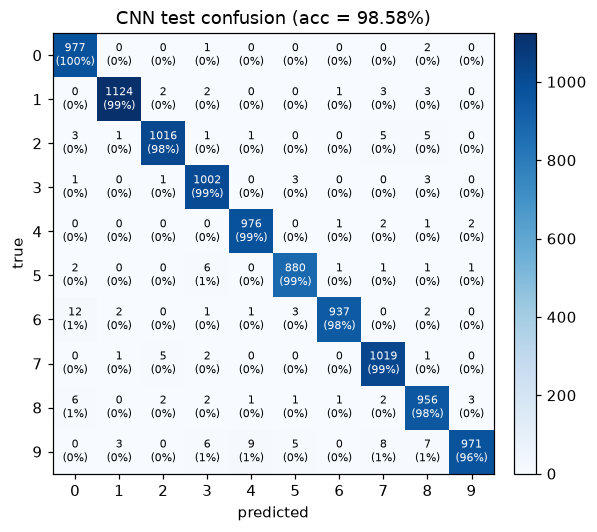

test errors: linear (Lab 1.1) = 791 | MLP (Lab 1.3) = 277 | CNN = 142
MLP 4→9 / 9→4: 13 15
CNN 4→9 / 9→4: 2 9
CNN top confusions (count, true → predicted): [(np.int64(12), 6, 0), (np.int64(9), 9, 4), (np.int64(8), 9, 7), (np.int64(7), 9, 8), (np.int64(6), 9, 3), (np.int64(6), 8, 0)]


In [8]:
mlp_pred = predict(mlp, X_test)
cnn_pred = predict(cnn, X_test)
cm = np.zeros((10, 10), dtype=int)
for t, p in zip(y_test, cnn_pred):
    cm[t, p] += 1

fig, ax = plt.subplots(figsize=(6, 5.2))
show_confusion(cm, list("0123456789"), ax=ax,
               title=f"CNN test confusion (acc = {(cnn_pred == y_test).mean():.2%})")
save_fig(fig, FIGS / "confusion.png"); plt.show()

print("test errors: linear (Lab 1.1) = 791 | MLP (Lab 1.3) = 277 |",
      f"CNN = {(cnn_pred != y_test).sum()}")
print("MLP 4→9 / 9→4:", ((mlp_pred == 9) & (y_test == 4)).sum(),
      ((mlp_pred == 4) & (y_test == 9)).sum())
print("CNN 4→9 / 9→4:", cm[4, 9], cm[9, 4])
off = sorted(((cm[i, j], i, j) for i in range(10) for j in range(10) if i != j), reverse=True)
print("CNN top confusions (count, true → predicted):", off[:6])

The error count falls **791 → 277 → 142**. The old 4→9 confusion drops from 13 to 2, though 9→4 remains at 9 and 9s supply several of the top remaining confusions. The new champion is 6→0 with 12 errors. Local reusable features fixed much of what the dense layers could not, but they did not make every ambiguous digit easy — nor should a 98.58% model have a single uniform failure mode.

## 6. The representation itself: what does a linear reader see?

Weight pictures ask, "what does this parameter multiply?" Representation analysis asks a different question: **after all this computation, how are examples arranged?**

Each image now has three descriptions:

- **pixels:** 784 raw intensities;
- **Lab 1.3 MLP:** 128 ReLU activations immediately before its output layer;
- **CNN:** 128 ReLU activations immediately before its output layer.

We use two instruments with different blind spots.

**t-SNE** compresses each cloud to two dimensions for visualization. Nearby points in a good t-SNE plot usually indicate local similarity in the original space; distances between far-apart clusters, cluster sizes, and the global layout are not reliable quantitative claims. It is a map for looking, not a proof of understanding.

A **linear probe** freezes the representation and trains only a new softmax readout. If a simple linear reader can recover the digit, that information is explicitly accessible in the geometry. If it cannot, that does not prove the information is absent — it may be nonlinearly encoded or the probe may have failed to optimize. Also, both networks already end in a linear classifier, so strong penultimate-layer probes are expected. The useful comparison is pixels → MLP → CNN, not surprise that the CNN's own classifier works.

In [9]:
@torch.no_grad()
def collect_features(model, x, device=device, batch_size=1000):
    model.eval()
    return torch.cat([model.features(xb.to(device)).cpu() for xb in x.split(batch_size)]).numpy()


probe_train_idx = rng.choice(len(X_train), size=5000, replace=False)
probe_test_idx = rng.choice(len(X_test), size=2000, replace=False)
Xtr_probe, Xte_probe = X_train[probe_train_idx], X_test[probe_test_idx]
ytr_probe, yte_probe = y_train[probe_train_idx], y_test[probe_test_idx]

features_train = {
    "pixels": x_train[probe_train_idx],
    "MLP hidden": collect_features(mlp, Xtr_probe),
    "CNN hidden": collect_features(cnn, Xtr_probe),
}
features_test = {
    "pixels": x_test[probe_test_idx],
    "MLP hidden": collect_features(mlp, Xte_probe),
    "CNN hidden": collect_features(cnn, Xte_probe),
}
print({name: value.shape for name, value in features_train.items()})

probe_scores = {}
for name in features_train:
    t0 = time.perf_counter()
    probe_model = LogisticRegression(max_iter=300, solver="lbfgs", random_state=SEED)
    probe_model.fit(features_train[name], ytr_probe)
    score = probe_model.score(features_test[name], yte_probe)
    probe_scores[name] = score
    print(f"linear probe on {name:10s}: test acc = {score:.4f} ({time.perf_counter() - t0:.1f}s)")

{'pixels': (5000, 784), 'MLP hidden': (5000, 128), 'CNN hidden': (5000, 128)}


linear probe on pixels    : test acc = 0.9120 (0.2s)


linear probe on MLP hidden: test acc = 0.9715 (0.1s)
linear probe on CNN hidden: test acc = 0.9900 (0.0s)


t-SNE on MLP hidden: 2.7s


t-SNE on CNN hidden: 2.3s
saved figure -> figures/lab04/representation_tsne.png


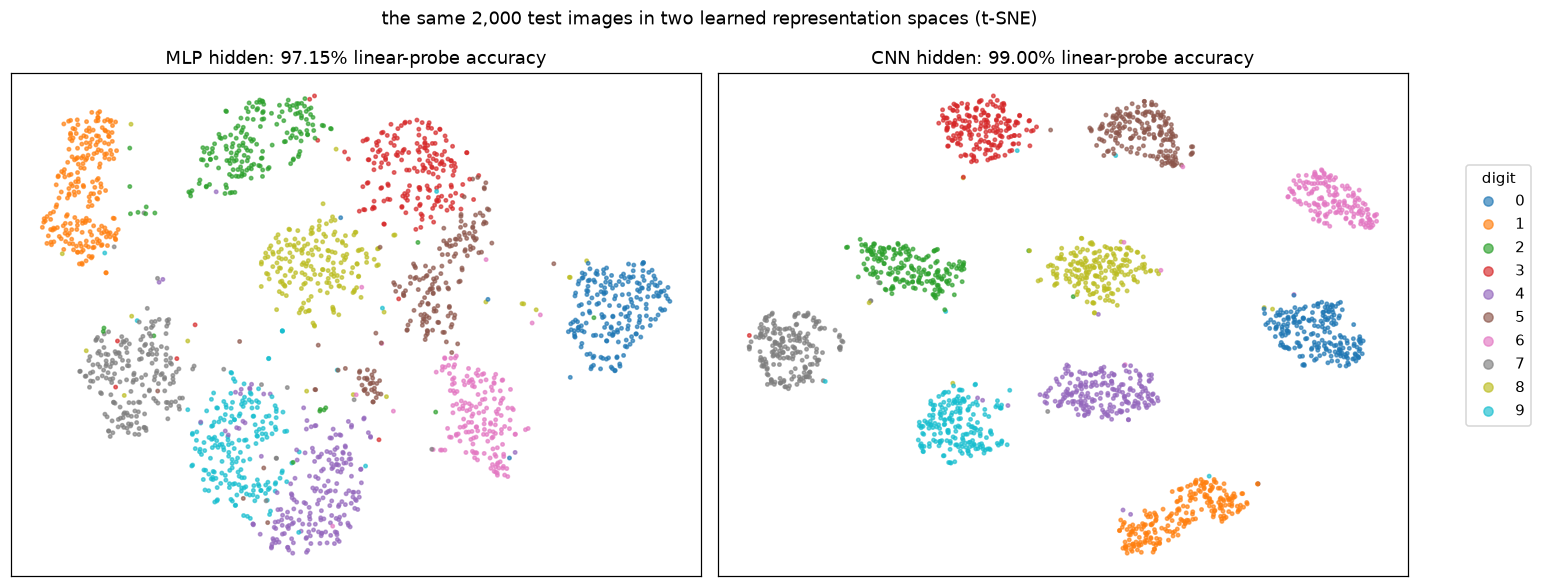

saved figure -> figures/lab04/linear_probes.png


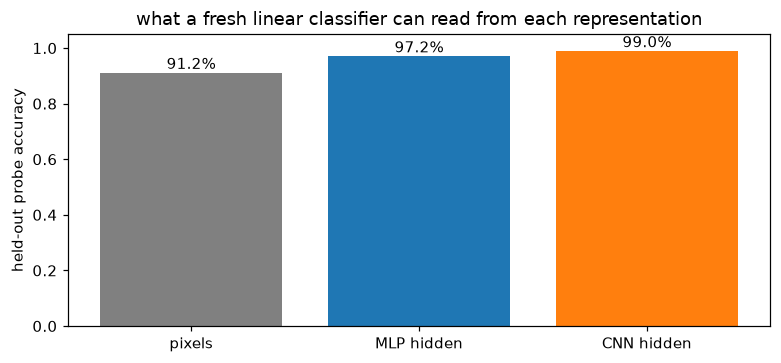

In [10]:
tsne_results = {}
for name in ("MLP hidden", "CNN hidden"):
    t0 = time.perf_counter()
    tsne_results[name] = TSNE(
        n_components=2, perplexity=35, init="pca", learning_rate="auto",
        max_iter=1000, random_state=SEED,
    ).fit_transform(features_test[name])
    print(f"t-SNE on {name}: {time.perf_counter() - t0:.1f}s")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
for ax, name in zip(axes, ("MLP hidden", "CNN hidden")):
    xy = tsne_results[name]
    scatter = ax.scatter(xy[:, 0], xy[:, 1], c=yte_probe, cmap="tab10", s=5, alpha=.65)
    ax.set_title(f"{name}: {probe_scores[name]:.2%} linear-probe accuracy")
    ax.set_xticks([]); ax.set_yticks([])
fig.legend(*scatter.legend_elements(), loc="center right", title="digit", bbox_to_anchor=(1.08, .5))
fig.suptitle("the same 2,000 test images in two learned representation spaces (t-SNE)")
fig.tight_layout(); save_fig(fig, FIGS / "representation_tsne.png"); plt.show()

fig, ax = plt.subplots(figsize=(7.2, 3.4))
names = list(probe_scores)
scores = [probe_scores[n] for n in names]
bars = ax.bar(names, scores, color=["grey", "tab:blue", "tab:orange"])
ax.bar_label(bars, labels=[f"{s:.1%}" for s in scores])
ax.set_ylim(0, 1.05); ax.set_ylabel("held-out probe accuracy")
ax.set_title("what a fresh linear classifier can read from each representation")
fig.tight_layout(); save_fig(fig, FIGS / "linear_probes.png"); plt.show()

save_ckpt(CKPT, "representation_analysis", metrics={},
          test_indices=probe_test_idx, labels=yte_probe,
          mlp_tsne=tsne_results["MLP hidden"], cnn_tsne=tsne_results["CNN hidden"],
          probe_names=np.array(names), probe_accuracy=np.array(scores));

The measured progression is **91.20% → 97.15% → 99.00%** for fresh linear probes trained on the same 5,000 examples and tested on the same 2,000 held-out images. The t-SNE maps show the corresponding change in neighborhood structure: the MLP has recognizable but still entangled class regions; the CNN forms visibly cleaner islands.

The maps and probes are two views of the same progression. Raw pixels contain the label, but a linear boundary must carve it out of highly entangled clouds. The MLP rearranges examples into more class-coherent neighborhoods. The CNN's penultimate space makes the classes still more directly readable.

Do not turn that into "the network stores a little label for every image." The output layer reads a **distributed representation**: 128 activations, reused across examples and classes, with geometry shaped by the classification loss. This is the same representational perspective as the embeddings note, except the vectors are now hidden activations computed from an image rather than rows looked up by token ID.

It also explains why probing is such a useful bridge toward Transformer interpretability. Once a residual stream contains contextual vectors, the same question becomes: can a small readout recover syntax, position, or a fact from that space? The probe never tells us *how* the network computed the feature, and high probe accuracy does not prove the downstream network actually uses it. For that causal question we still need the lesion spirit of Lab 1.3.

## 7. What we actually established

**The framework change was exactly no model change.** The Lab 1.3 checkpoint ran in PyTorch with matching forward logits, autograd gradients matched the hand formulas, and MPS preserved its test behavior. The interesting differences start only when the architecture changes.

**A convolutional weight is not a miniature class template.** It is a local, reusable question asked at every position. Its output is a response map, and shifting the input shifts that map exactly — equivariance, demonstrated numerically. Later layers still have to convert those moving responses into a class decision.

**Weight sharing buys robustness, not magical invariance.** The CNN tolerated shifted MNIST better than the dense MLP, but accuracy still degraded under larger translations. The flattened dense head remains position-sensitive. Architecture supplied an inductive bias; it did not repeal the data distribution.

**The advantage is visible in representation space.** Linear probes quantify what a simple readout can recover from pixels, MLP activations, and CNN activations; t-SNE makes the corresponding neighborhood structure visible. Neither tool replaces causal analysis, and neither assigns every neuron a clean concept.

The series has now changed instruments three times: weight images for linear templates, activation maximization and lesions for hidden features, response maps and probes for shared representations. Those instruments will transfer directly to attention and Transformer internals — but attention adds content-dependent routing, which is a new experiment, not just another weight picture.

**Natural next experiments:**

1. replace the dense head with global average pooling and rerun the shift curve;
2. train with random translations to separate architectural bias from data augmentation;
3. lesion entire CNN channels and measure which classes lose which visual evidence;
4. carry the probe methodology into Lab 2's attention and residual-stream representations.

**Reading:**

- LeCun et al., [*Gradient-Based Learning Applied to Document Recognition*](http://yann.lecun.com/exdb/publis/pdf/lecun-98.pdf) (1998) — convolution, subsampling, and weight sharing in their original MNIST context.
- Dumoulin & Visin, [*A guide to convolution arithmetic for deep learning*](https://arxiv.org/abs/1603.07285) (2016) — the clearest reference for shapes, padding, and strides.
- van der Maaten & Hinton, [*Visualizing Data using t-SNE*](https://jmlr.org/papers/v9/vandermaaten08a.html) (2008) — what the visualization optimizes, and why its local structure matters more than global distances.
- Alain & Bengio, [*Understanding intermediate layers using linear classifier probes*](https://arxiv.org/abs/1610.01644) (2016) — the probing method used above.

---

### Reproduce

```bash
cd labs/ml/mnist-internals
source .venv/bin/activate
jupyter lab     # open 04_weight_sharing_and_representations.ipynb
```

Artifacts: `checkpoints/lab04/` (imported MLP, every CNN epoch, shift measurements, t-SNE/probe arrays + `manifest.json`) and `figures/lab04/*.png`.

In [11]:
print("checkpoints written this lab:")
for entry in manifest(CKPT):
    print(f"  {entry['name']:<24} step={str(entry['step']):<6} metrics={entry['metrics']}")

checkpoints written this lab:
  mlp_lab03_imported       step=5616   metrics={'test_loss': 0.09783, 'test_acc': 0.9723}
  cnn_epoch_1              step=235    metrics={'test_loss': 0.11406, 'test_acc': 0.964}
  cnn_epoch_2              step=470    metrics={'test_loss': 0.06562, 'test_acc': 0.9801}
  cnn_epoch_3              step=705    metrics={'test_loss': 0.05709, 'test_acc': 0.982}
  cnn_epoch_4              step=940    metrics={'test_loss': 0.04484, 'test_acc': 0.9846}
  cnn_epoch_5              step=1175   metrics={'test_loss': 0.04167, 'test_acc': 0.9857}
  cnn_epoch_6              step=1410   metrics={'test_loss': 0.03868, 'test_acc': 0.9858}
  shift_experiment         step=None   metrics={}
  representation_analysis  step=None   metrics={}
